# DQN の骨格 — ReplayBuffer と ターゲットネットワーク

**出典**　機械学習 4 分野の教科書 — 第 11 章 4-A MDP と価値ベース ／ 07 実装：表形式 Q 学習から DQN の骨格まで

**このノートのパス**　`ml-code/11_mdp_q/02_dqn_skeleton.ipynb`

**このノートで確かめること**
教科書が骨格だけ示した部分を、**CartPole で実際に学習が進むところまで**繋ぐ。
**経験再生で相関を切る**ことと、**ターゲットネットワークを定期的に同期する**ことの意味を確かめる。

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `gymnasium torch numpy` |
| 実行時間の目安 | 約 2〜4 分 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [2]:
# 未導入なら実行する（Colab など）
# !pip install -q gymnasium torch numpy

In [3]:
import random, collections
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

Transition = collections.namedtuple("Transition", "s a r s2 done")

class ReplayBuffer:
    def __init__(self, capacity=50_000):
        self.buf = collections.deque(maxlen=capacity)
    def push(self, *args):
        self.buf.append(Transition(*args))
    def sample(self, batch_size):
        batch = random.sample(self.buf, batch_size)      # ← 相関を切る
        return Transition(*map(np.array, zip(*batch)))
    def __len__(self):
        return len(self.buf)


class QNet(nn.Module):
    """状態を入れると、全行動の Q 値をまとめて出す"""
    def __init__(self, obs_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),          # 出力は行動数ぶん
        )
    def forward(self, x):
        return self.net(x)


def train_step(q, q_target, opt, batch, gamma=0.99):
    s  = torch.as_tensor(batch.s,  dtype=torch.float32)
    a  = torch.as_tensor(batch.a,  dtype=torch.int64).unsqueeze(1)
    r  = torch.as_tensor(batch.r,  dtype=torch.float32).unsqueeze(1)
    s2 = torch.as_tensor(batch.s2, dtype=torch.float32)
    d  = torch.as_tensor(batch.done, dtype=torch.float32).unsqueeze(1)

    q_sa = q(s).gather(1, a)                       # 実際に取った行動の Q 値

    with torch.no_grad():                          # ターゲットは勾配を流さない
        q_next = q_target(s2).max(dim=1, keepdim=True).values
        target = r + gamma * q_next * (1.0 - d)    # 終端なら将来価値なし

    loss = F.smooth_l1_loss(q_sa, target)          # Huber 損失（外れ値に強い）
    opt.zero_grad(); loss.backward()
    nn.utils.clip_grad_norm_(q.parameters(), 10.0) # 勾配クリッピング
    opt.step()
    return loss.item()

## 学習ループ — 骨格の 4 ステップをそのまま実装する

1. ε-greedy で行動 → 環境を 1 ステップ進める
2. 経験をバッファに push
3. バッファが十分たまったら sample して `train_step`
4. 一定ステップごとに `q_target.load_state_dict(q.state_dict())`

In [4]:
import gymnasium as gym

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

env = gym.make("CartPole-v1")
obs_dim = env.observation_space.shape[0]
n_actions = env.action_space.n

q = QNet(obs_dim, n_actions)
q_target = QNet(obs_dim, n_actions)
q_target.load_state_dict(q.state_dict())
opt = torch.optim.Adam(q.parameters(), lr=1e-3)
buf = ReplayBuffer()

BATCH, WARMUP, SYNC_EVERY = 64, 1_000, 500
eps, eps_min, eps_decay = 1.0, 0.05, 0.995
TOTAL_EPISODES = 250          # 増やすほど安定する

returns, step_count = [], 0
for ep in range(TOTAL_EPISODES):
    s, _ = env.reset(seed=SEED) if ep == 0 else env.reset()
    done, total = False, 0.0
    while not done:
        # 1. ε-greedy で行動
        if random.random() < eps:
            a = env.action_space.sample()
        else:
            with torch.no_grad():
                a = int(q(torch.as_tensor(s, dtype=torch.float32)).argmax())

        s2, r, terminated, truncated, _ = env.step(a)
        done = terminated or truncated
        # ⚠️ done ではなく terminated を積む。時間切れ(truncated)では将来価値を切らない
        buf.push(s, a, r, s2, float(terminated))
        s = s2; total += r; step_count += 1

        # 3. 十分たまったら学習
        if len(buf) >= WARMUP:
            train_step(q, q_target, opt, buf.sample(BATCH))
        # 4. 定期的にターゲットを同期
        if step_count % SYNC_EVERY == 0:
            q_target.load_state_dict(q.state_dict())

    returns.append(total)
    eps = max(eps_min, eps * eps_decay)
    if (ep + 1) % 50 == 0:
        print(f"episode {ep+1:4d}  直近50の平均得点 = {np.mean(returns[-50:]):6.1f}  "
              f"eps={eps:.3f}", flush=True)

env.close()

episode   50  直近50の平均得点 =   20.2  eps=0.778


episode  100  直近50の平均得点 =   17.5  eps=0.606


episode  150  直近50の平均得点 =   27.7  eps=0.471


episode  200  直近50の平均得点 =   66.3  eps=0.367


episode  250  直近50の平均得点 =   60.8  eps=0.286


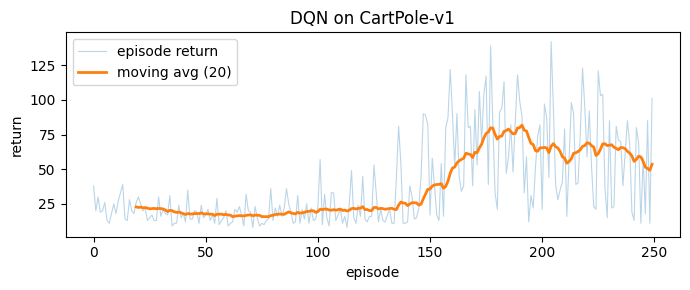

In [5]:
import matplotlib.pyplot as plt

w = 20
ma = np.convolve(returns, np.ones(w) / w, mode="valid")
plt.figure(figsize=(7, 3))
plt.plot(returns, alpha=.3, lw=.8, label="episode return")
plt.plot(range(w - 1, len(returns)), ma, lw=2, label=f"moving avg ({w})")
plt.xlabel("episode"); plt.ylabel("return"); plt.legend()
plt.title("DQN on CartPole-v1"); plt.tight_layout(); plt.show()

## 読み取りどころ

- **経験再生（ReplayBuffer）が相関を切る。**連続したステップは強く相関しており、そのまま学習すると勾配が偏る。`random.sample` でシャッフルすることが**学習の安定に効く**。
- **ターゲットネットワークが「動く的」を止める。**`q` 自身で target を作ると、更新のたびに目標も動いて発散しやすい。定期同期でしばらく固定する。
- ⚠️ **バッファに積むのは `terminated` であって `done` ではない。**CartPole は 500 ステップで `truncated` するが、これは本当の終端ではない。ここを間違えると「長く粘ると損」と学習してしまう。
- **`smooth_l1_loss`（Huber）を使うのは、TD 誤差に外れ値が出やすいため。**二乗誤差だと 1 つの大きな誤差で勾配が跳ねる。

⚠️ **強化学習は分散が大きい。**得点のグラフはギザギザになり、一度上がってから崩れることもある（破滅的忘却）。**1 回の実行で結論を出さず、seed を変えて複数回走らせること。**